# Activity 3B — Process a scientific image

**COM7024 · Lesson 7 · SciPy**  
Real question: How do blur, rotation and edges change what we see? Suggested time: 20 minutes.

**How to use:** Run the cells from top to bottom. Every example works with the supplied full dataset.

## Step 0 — Find the data folder

This short setup supports your GitHub layout: `app/L7/` for notebooks and `data/` at the repository root.

In [2]:
from pathlib import Path

# The data folder is at the root of your GitHub repository.
DATA = Path("data")                 # If Jupyter starts at the repository root
if not DATA.exists():
    DATA = Path("../../data")       # If Jupyter starts inside app/L7
if not DATA.exists():
    DATA = Path("../data")          # If notebooks are in a separate folder

print("Data folder:", DATA.resolve())

Data folder: /workspaces/ProgrammongForDA/data


## 1. Find the dataset folder

Use the same shared data folder as the other activities.

In [3]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

## 2. Open the picture as numbers

A greyscale image is a two-dimensional array of pixel values.

Image shape: (512, 512)
Smallest pixel value: 0
Largest pixel value: 255


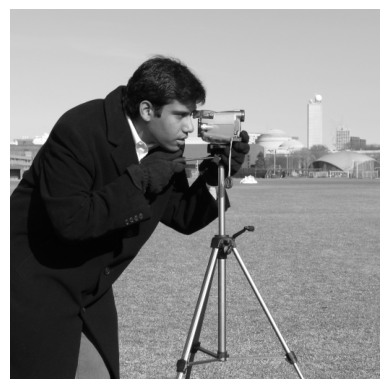

In [4]:
image = np.array(Image.open(DATA / "Camera_Practice_Image.png").convert("L"))
print("Image shape:", image.shape)
print("Smallest pixel value:", image.min())
print("Largest pixel value:", image.max())
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

## 3. Blur the picture

A Gaussian filter reduces fine detail. A larger `sigma` means more smoothing.

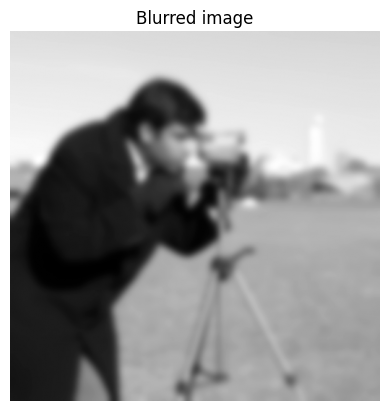

In [9]:
blurred = ndimage.gaussian_filter(image, sigma=5)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred image")
plt.axis("off")
plt.show()

## 4. Rotate the picture

`reshape=False` keeps the original image size; some corners may be cropped.

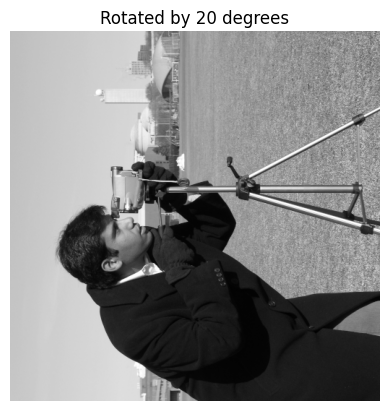

In [10]:
rotated = ndimage.rotate(image, 90, reshape=False)
plt.imshow(rotated, cmap="gray")
plt.title("Rotated by 20 degrees")
plt.axis("off")
plt.show()

## 5. Find edges

The Sobel filter highlights places where brightness changes quickly.

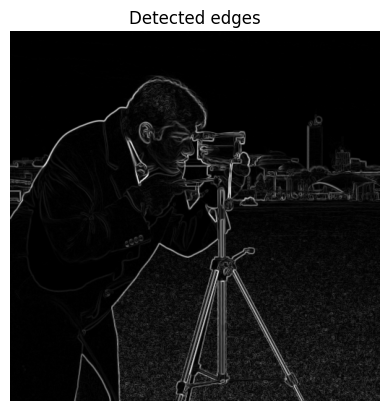

In [7]:
edges_x = ndimage.sobel(image.astype(float), axis=0)
edges_y = ndimage.sobel(image.astype(float), axis=1)
edges = np.hypot(edges_x, edges_y)
plt.imshow(edges, cmap="gray")
plt.title("Detected edges")
plt.axis("off")
plt.show()

## 6. Compare the original and processed images

Put three images next to one another for discussion.

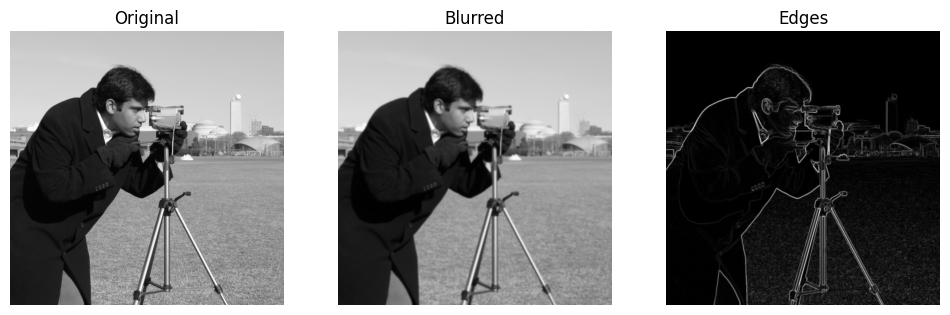

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(blurred, cmap="gray")
axes[1].set_title("Blurred")
axes[2].imshow(edges, cmap="gray")
axes[2].set_title("Edges")
for ax in axes:
    ax.axis("off")
plt.show()

## Your turn — Quick challenge

Try `sigma=1` and `sigma=6`. Which version preserves more detail? Which removes more noise?

### Before you finish

**Interpretation:** Filters help us inspect images but can remove or change information. Keep the original image when reporting results.